<a href="https://colab.research.google.com/github/mariobet23440/Proyecto-3---M-todos-Num-ricos-1/blob/main/Proyecto3MetodosNumericos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***MOTOR DC - GEMELO DIGITAL Y CONTROL PID***

```Proyecto 3 - Métodos Numéricos 1```

***Creado por:***
*   Mario Betancourt (23440)
*   Pongan sus nombres y (carnets)

## ***HISTORIAL DE REVISIONES***
*   21/11/2026 - Creación de archivo y método de Euler
*   22/11/2026 - Correcciones al desarrollo matemático de la Parte 1, revisadas y aprobadas por el equipo (ver `UsoIA/`)



# ***INTRODUCCIÓN***
Le damos la bienvenida al cuaderno de Jupyter del Proyecto 3 del curso Métodos Numéricos 1 de la Universidad del Valle de Guatemala. En este proyecto trabajaremos en la aplicación de métodos numéricos para calcular derivadas e integrales y métodos de resolución de ecuaciones diferenciales al análisis de la dinámica de un motor DC.

De acuerdo con la guía, el motor DC se modela a través de un sistema de tres ecuaciones diferenciales acopladas:

$$\begin{cases}
L\frac{di}{dt} = V-Ri-K_e \omega \\
J_m\frac{d\omega}{dt} = K_t i - b\omega -\tau_c \text{ sign}(\omega) - \tau_{carga} \\
\frac{d\theta}{dt} = \omega
\end{cases}$$

Donde los símbolos representan las siguientes cantidades físicas

*   $L$ - Inductancia del motor [henrios, H]
*   $V$ - Voltaje aplicado en las terminales del motor [Volts, V]
*   $R$ - Resistencia del motor [Ohms, $\Omega$]
*   $K_e$ - Constante de fuerza contraelectromotriz [$V/(rad/s)$]
*   $\omega$ - Velocidad angular del motor [radianes por segundo, $rad/s$]
*   $J_m$ - Inercia del eje del motor [$\text{kg}\cdot\text{m}^2$]
*   $K_t$ - Constante de torque del motor [$\text{N}\cdot\text{m}/\text{A}$]
*   $b$ - Coeficiente de amortiguamiento viscoso [$\text{N}\cdot\text{m}\cdot\text{s}/\text{rad}$]
*   $\tau_c$ - Torque de fricción de Coulomb [$\text{N}\cdot\text{m}$]
*   $\tau_{carga}$ - Torque de carga [$\text{N}\cdot\text{m}$]

Un estudio de estos modelos en cursos de sistemas de control sugiere que el sistema de ecuaciones representa a un motor DC controlado por armadura. Este modelo de motores DC supone que la corriente en el estator (corriente de campo) es constante y el control de movimiento se realiza por la corriente del devanado del rotor (devanado de armadura). Este modelo de motores es aplicable también a motores DC de imanes permanentes. El motor DC JGA25-370 entra dentro de esta categoría. Para más información, véase Nise

(AGREGAR REFERENCIA POR FAVOR, capítulo 4 no recuerdo donde estaba)


A diferencia del modelo lineal presentado en Nise (no sé, no sé, no sé) el modelo analizado en este proyecto agrega una dificultad adicional: *se considera un término no lineal para la fricción de Coulomb*. Aunque es posible linealizar el sistema y analizarlo a través de Transformadas de Laplace (como se hace en Sistemas de Control 1), ese no es el objetivo de este proyecto. Al fin y al cabo, el objetivo de este curso no es simplificar el modelo, sino resolverlo numéricamente tal cual. Por lo tanto, a diferencia de lo que se haría en un análisis de sistemas lineales, en este proyecto resolveremos la ecuación original con todas sus no linealidades.

# ***PARTE 1 - SOLUCIÓN DE SISTEMAS DE ECUACIONES DIFERENCIALES***

Ahora que fijamos como objetivo resolver el sistema de ecuaciones diferenciales mostrado anteriormente, surge la importante pregunta de cómo debemos proceder. Empecemos tratando de entender cómo resolver un sistema de ecuaciones a través del método de Euler.

## **1.1. El Método de Euler para una EDO de primer orden**
El método de Euler es fácil y muy intuitivo de definir para un Problema de Valores Iniciales (PVI) con una EDO de primer orden:

$$\begin{cases}
\frac{dy}{dx}=f(x,y)\\
y(x_0) = y_0
\end{cases}
$$

Donde $x_0$ y $y_0$ son constantes arbitrarias. Para aproximar la solución a este PVI, utilizamos diferencias finitas hacia adelante para aproximar la derivada en $x_k$ usando el intervalo $[x_k, x_{k+1}]$, donde $x_{k+1} = x_k + h$:

$$\frac{dy}{dx} \approx \frac{y_{k+1} - y_k}{h} $$

Donde $y_{k+1} \approx y(x_{k+1})$ y $y_{k} \approx y(x_{k})$ son las **aproximaciones numéricas** de la variable dependiente en los extremos del intervalo antes definido. (En la sección 1.4 se usará una letra mayúscula para distinguir la solución exacta).

Al sustituir en la EDO, evaluando $f$ en el extremo izquierdo del intervalo, $(x_k, y_k)$:
$$\frac{y_{k+1} - y_k}{h}\approx f(x_k,y_k)$$

Evaluar $f$ en el extremo izquierdo es justamente lo que hace que el método sea **explícito**; evaluarla en $(x_{k+1}, y_{k+1})$ daría el método de Euler implícito.

Resuelva para $y_{k+1}$ y obtendrá la ecuación del método de Euler explícito (el método de Euler que aproxima la solución extrapolando hacia adelante usando la derivada en el punto actual):

$$y_{k+1} = y_k + hf(x_k, y_k)$$

¿Ve lo simple que es llegar a este famoso método?



## **1.2. El Método de Euler para un sistema de EDOs de primer orden**
Ahora extrapolemos esta deducción hacia un sistema de varias EDOs de variables dependientes en el vector $\mathbf{y}=[y_1, y_2, ..., y_N]^T$. ¿Qué tanto podría cambiar?

Suponga que todas las ecuaciones del sistema pueden escribirse en forma canónica (aunque el lado derecho sea una no linealidad espeluznante):

$$
\begin{cases}
y_1' = f_1(x,y_1,y_2, ..., y_N)\\
y_2' = f_2(x,y_1,y_2, ..., y_N)\\
y_3' = f_3(x,y_1,y_2, ..., y_N)\\
\vdots \\
y_N' = f_N(x,y_1,y_2, ..., y_N)
\end{cases}
$$

Aunque no lo crea, este sistema de ecuaciones grita que puede ser expresado en forma vectorial. Reúna las variables dependientes en el vector $\mathbf{y}$ y los lados derechos en una sola función vectorial $\mathbf{f}$, el **campo vectorial** del sistema:

$$
\mathbf{y} = \begin{pmatrix} y_1 \\ y_2 \\ \vdots \\ y_N \end{pmatrix},\qquad
\mathbf{f}(x,\mathbf{y}) = \begin{pmatrix} f_1(x,\mathbf{y}) \\ f_2(x,\mathbf{y}) \\ \vdots \\ f_N(x,\mathbf{y}) \end{pmatrix}
$$

Si recuerda que derivar una función vectorial equivale a derivar cada una de sus componentes, $\mathbf{y}' = [y_1', y_2', ..., y_N']^T$, todo el sistema cabe en una sola línea:

$$\mathbf{y}' = \mathbf{f}(x,\mathbf{y})$$

¡Para sistemas de EDOs de primer orden, la función de pendiente escalar $f(x,y)$ se reemplaza por un campo vectorial $\mathbf{f}(x,\mathbf{y})$!

Resolver el sistema de ecuaciones mediante el método de Euler es realmente sencillo: aproxime la derivada de cada variable dependiente en el sistema a través de diferencias finitas y resuelva para el valor de la función en el extremo derecho del intervalo sobre el que se aproxima. Básicamente, haga lo mismo que hicimos antes para deducir que $y_{k+1} = y_k + hf(x_k, y_k)$ pero *por cada función $y_i$ en el sistema de EDOs*.

De esta forma, por cada iteración $k$, $x_k = x_0 + hk$ y por cada variable dependiente:

$$
\begin{aligned}
(y_1)_{k+1} &= (y_1)_{k} + h f_1 (x_k, (y_1)_k, (y_2)_k, ..., (y_N)_k)\\
(y_2)_{k+1} &= (y_2)_{k} + h f_2 (x_k, (y_1)_k, (y_2)_k, ..., (y_N)_k)\\
&\ \ \vdots\\
(y_N)_{k+1} &= (y_N)_{k} + h f_N (x_k, (y_1)_k, (y_2)_k, ..., (y_N)_k)
\end{aligned}
$$

Estas $N$ fórmulas son exactamente las componentes de una sola ecuación vectorial. Por lo tanto, para un sistema de ecuaciones la fórmula iterativa del método de Euler puede reescribirse en forma vectorial:

$$\mathbf{y}_{k+1} =\mathbf{y}_{k} + h\,\mathbf{f}(x_k, \mathbf{y}_{k})$$

Esta forma de expresar la fórmula iterativa del método de Euler es extremadamente importante. Por favor, recuérdela, que será de mucha utilidad cuando tratemos de estudiar la estabilidad del método en este caso.

## **1.3. Sistemas de EDOs de orden superior**
Ahora considere que agregamos la complejidad adicional de que en nuestro sistema de ecuaciones: tenemos al menos una ecuación con una derivada de orden superior de una variable dependiente. La solución, en este caso, es bastante simple: *reemplace la derivada de orden superior por una derivada de primer orden utilizando variables auxiliares*.

Para ilustrar mejor esta idea, olvide que tratamos con sistemas de ecuaciones y considere lo que ocurre con una sola EDO de segundo orden:

$$\frac{d^2y}{dt^2} = \frac{dy}{dt} - 1$$

En este caso, podemos convertir la ecuación de segundo orden en un *sistema* de ecuaciones de primer orden sustituyendo la derivada de segundo orden por la derivada de una variable auxiliar. Considere que $u_1 = y$ y $u_2 = y'$. Para este problema se obtiene el sistema de EDOs de primer orden:

$$\begin{cases}
\frac{du_2}{dt}= u_2 - 1\\
\frac{du_1}{dt}= u_2
\end{cases}
$$

Por lo tanto, en un sistema de ecuaciones donde aparecen múltiples EDOs de orden superior, cada EDO de orden $n$ se descompone en exactamente $n$ EDOs de primer orden, usando las variables auxiliares $u_1 = y,\ u_2 = y',\ \dots,\ u_n = y^{(n-1)}$. En este ejemplo, dado que la ecuación era de segundo orden (orden 2), se necesitaron 2 ecuaciones de primer orden.

Observe que el modelo del motor ya está escrito como un sistema de primer orden, con vector de estado $\mathbf{y} = [i,\ \omega,\ \theta]^T$: la ecuación $\frac{d\theta}{dt} = \omega$ es justamente la reducción de orden de la ecuación de segundo orden para $\theta$.

Con esto mencionado, ya tenemos la teoría suficiente para (1) aplicar el método de Euler y generalizar a otros métodos para resolver EDOs vistos en el curso y (2) Analizar la estabilidad de la solución numérica, al menos para el método de Euler.

## **1.4. Estabilidad Numérica del Método de Euler**
Suponga que la solución exacta del sistema de EDOs en $x_k$ es $\mathbf{Y}(x_k)$ (observe que se usó una letra mayúscula). Esta puede calcularse de forma exacta en las cercanías de $x_k$ al utilizar series de Taylor y agregar un término de error local $\mathbf{T}_k$ por los términos de orden superior:

$$\mathbf{Y}(x_{k+1}) = \mathbf{Y}(x_k) + h\,\mathbf{f}(x_k, \mathbf{Y}(x_k)) + \mathbf{T}_k$$

Como $\mathbf{Y}$ es una función vectorial, el residuo de Taylor se escribe componente a componente: cada componente tiene su propio punto intermedio $\epsilon_i \in (x_k, x_{k+1})$,

$$(\mathbf{T}_k)_i = \frac{h^2}{2}\,Y_i''(\epsilon_i), \qquad i = 1, 2, \dots, N$$

En general no existe un único $\epsilon$ que sirva para todas las componentes a la vez. Lo que sí se puede afirmar es la cota

$$\|\mathbf{T}_k\| \le \frac{h^2}{2}\max_{x\in[x_k,x_{k+1}]}\|\mathbf{Y}''(x)\|$$

Definimos el error en el paso $k$ como $\mathbf{e}_{k} = \mathbf{Y}(x_{k}) - \mathbf{y}_{k}$. Al restar la fórmula de Euler $\mathbf{y}_{k+1} = \mathbf{y}_k + h\,\mathbf{f}(x_k, \mathbf{y}_k)$ de la expansión de Taylor, el error en el paso $k+1$ es:

$$\mathbf{e}_{k+1} = \mathbf{Y}(x_{k+1}) - \mathbf{y}_{k+1} = [\mathbf{Y}(x_k)-\mathbf{y}_{k}] + h[\mathbf{f}(x_k, \mathbf{Y}(x_k)) - \mathbf{f}(x_k, \mathbf{y}_k)] + \mathbf{T}_k$$

Este error tiene tres componentes:
- $\mathbf{Y}(x_{k+1}) - \mathbf{y}_{k+1}$ es el error global acumulado hasta el paso $k$.
- $h[\mathbf{f}(x_k, \mathbf{Y}(x_k)) - \mathbf{f}(x_k, \mathbf{y}_k)]$ es el error propagado por la pendiente: muestra cómo el error en el paso anterior influye en el error de la pendiente del paso siguiente.
- $\mathbf{T}_k$ es el error de truncamiento local, se agrega por la Serie de Taylor.

Un método de resolución de sistemas de EDOs es **numéricamente estable** si conforme $k$ aumenta, la solución numérica converge a la solución analítica y no explota (en pocas palabras).

Para ser completamente honestos con usted, en esta parte no supimos cómo proceder. La mayoría de videos en internet que hablan respecto al tema utilizan el Jacobiano bajo el supuesto de que los sistemas de EDOs que se resuelven son lineales. Al consultar con Claude AI (2026) sobre cómo se debería proceder con el análisis que estamos haciendo, esta sugirió que la ****

# ***PARTE 2 - DERIVACIÓN NUMÉRICA***
El motor utilizado en la parte experimental, el modelo JGA25-370, permite medir en tiempo real la velocidad angular del eje a través de un dispositivo conocido como un *encoder de cuadratura de efecto Hall*.


## **2.1. Encoders de Cuadratura de Efecto Hall**
En este dispositivo se colocan varios imanes de polos alterantes sobre una rueda que está acoplada mecánicamente al eje del motor. Fuera de la rueda y fijos a la carcasa del motor, se colocan dos sensores de campo magnético en posiciones angulares distintas respecto al eje. Sus señales por lo general se denominan canales *A* y *B*.  La disposición de los sensores es tal que hay un intervalo de tiempo donde los sensores dan lecturas distintas: uno detecta campo magnético entrante hacia su dirección mientras que el otro detecta un campo saliente. Por lo general, los intervalos de tiempo donde las lecturas difieren duran lo mismo que los intervalos de tiempo donde las lecturas son iguales.

Conforme el eje gira los sensores miden un campo magnético oscilante. Debido a su disposición alrededor de la rueda, estos miden señales iguales pero desfasadas entre sí. Al reconocer cuál de las dos señales se activa primero, podemos saber hacia qué dirección gira el motor. Si contamos cuántas oscilaciones hay durante una revolución del eje y medimos cuántas oscilaciones hay en un intervalo de tiempo mientras el rotor gira, podemos calcular la velocidad angular del motor.

Desafortunadamente los encoders de cuadratura por efecto Hall tienen una limitante importante: *no permiten saber cuándo ocurre una revolución*. En otros tipos encoders, la solución a este problema es la inclusión de un tercer canal, un canal de índice de número Z. Esta limitante dificulta la medición precisa de la posición angular el tiempo real.

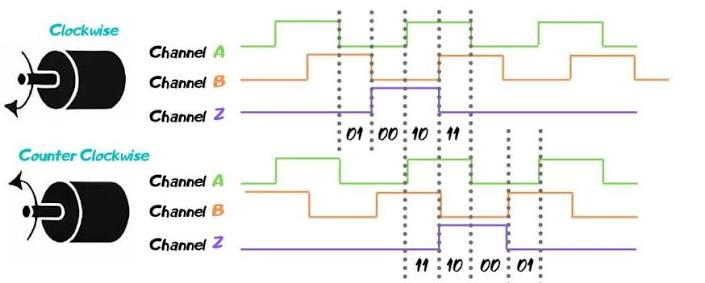

Suponga que los sensores contienen $N$ imanes y que los intervalos de tiempo donde las lecturas de los canales A y B coinciden y difieren son iguales y de duración $\Delta t$. La duración del intervalo donde un canal produce una señal lógica alta es $2\Delta t$ y un ciclo tiene duración $4\Delta t$.

Asumiendo que los imanes producen campos magnéticos alternantes sobre sectores circulares iguales, el desplazamiento angular (en radianes) ocupado por cada sector es:
$$\Delta \theta = \frac{2\pi}{N} \quad \text{ [rad]}$$

Por lo tanto, dado que el tiempo en que la dirección del campo magnético en uno de los sensores se mantiene es $2\Delta t$, la velocidad angular promedio medida durante este intervalo es:

$$\omega_m = \frac{\pi}{N \Delta t} \quad \text{ [rad/s]}$$

Usando periféricos temporizadores y capturadores de onda, podemos medir la duración de $\Delta t$ o alguno de sus múltiplos relevantes.

Por simetría radial, se puede deducir que un motor con encoder por sensores de efecto Hall debe tener un número par de imanes. En caso contrario, habrían dos polos de la misma polaridad adyacentes y el sensor no produciría pulsos uniformes. Por lo tanto, si durante un ciclo hay tantos polos 'salientes' como 'entrantes' a los sensores, es lógico que si contamos cuántas veces cambia la señal, el número de imanes es ese valor.

Los microcontroladores son muy buenos para contar cuántas veces ocurre un flanco de cierto tipo (flancos positivos o flancos negativos). Sea $n_F$ el número de flancos positivos que ocurre durante una revolución del eje del motor. A partir de este número fácilmente medible en la práctica, podemos calcular el número de imanes a través de:

$$N = \frac{n_F}{2}$$


## **2.2. Medición de la posición angular**
Dado que no se dispone de un canal de índice, se propone un esquema artesanal para medir la posición angular del eje. Después de un evento (e.g. el reinicio del microcontrolador) podemos iniciar un contador de flancos que cuente cuántas veces ocurre un *flanco de cualquier tipo (positivo o negativo)* en uno de los dos canales. Usando la cuadratura, podemos saber también en qué dirección gira el eje del motor. De esta forma, podemos incrementar o decrementar el contador según el signo de la velocidad angular. Finalmente, podemos multiplicar el contador de cambios por el desplazamiento angular por polo de la rueda del encoder calculado previamente (una constante del encoder) y obtener una estimación de la posición angular actual $\theta = C (\Delta \theta)$.

Para explicarlo mejor, se propone el siguiente pseudocódigo

CONSTANTE delta_theta
1. Inicialice INT $C$
2. Inicialice un PIN de entrada PIN_A
3. WHILE(TRUE):
4.      BOOL A_curr = READ(PIN_A) %Estado del pin A en la iteración actual
5.      IF(A_curr != A_prev):
            omega = MEDIR_VELOCIDAD_ANGULAR
            C = C + SIGN(omega)
            theta = C * delta_theta

Este método puede ser funcional siempre y cuándo el intervalo de tiempo entre dos lecturas del pin que monitorea el sensor de cuadratura sea significativamente menor al periodo de rotación del eje del rotor. Dado que las constantes de tiempo características mecánicas del sistemas on mucho mayores a las constantes de tiempo característicos de la parte eléctrica, esto es viable y factible.

Una observación importante acerca de este esquema es que la posición angular no está acotada entre $0$ y $2\pi$, y se permite que esta incremente más alla. Esto no ocasiona problema alguno dado que son ángulos que corresponden a varias revoluciones.

Un detalle interesante acerca de este esquema es que, porque los desplazamientos angulares donde la polaridad del campo magnético cambia son constantes sobre toda la rueda, *la magnitud de la posición angular se cuantiza*. Esto significa que cualquier posición angular es un múltiplo entero de $\Delta \theta$. Esto limita la resolución del problema y fuerza a no tratar a la velocidad angular como una cantidad continua.

Ahora sí, con esta discusión hecha, ya podemos entender cómo podemos aplicar los métodos de derivación numérica que estudiamos en el curso y algunos posibles retos a ser observados.

## **2.2. Aplicación de métodos de diferenciación numérica**
En este caso, lo que obtendremos del experimento son mediciones del tiempo y la posición angular estimada con el encoder. En otras palabras, para el dato $k$ tendremos un par de datos $(t_k, \theta_k)$. Podemos usar los métodos de diferencias finitas y otros más para aproximar la derivada la posición angular respecto del tiempo y así obtener la velocidad angular como una función del tiempo.



Por sí solo, un encoder de cuadratura permite